# 05 · Joint residual risk and diffusion clocks

**RQ2–RQ3:** Can explicit residual risk repair the smooth-factor model? Does
stochastic time scaling explain some calendar-gap behavior? This is a revised
development model, distinct from the frozen source-covariance benchmark.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

from spde_covariance.empirical_research import load_research_evidence

evidence = load_research_evidence(Path("../experiments/results/shfe-research"))
print(evidence["protocol"]["status"])
print("Numerical source:", evidence["manifest"]["git_revision"])
print("Original baseline source:", evidence["protocol"]["baseline_source_revision"])
assert evidence["protocol"]["baseline_summary_sha256"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def table(rows, columns):
    print(" | ".join(columns))
    for row in rows:
        print(
            " | ".join(
                (
                    f"{row.get(c):.6g}" if isinstance(row.get(c), float) else str(row.get(c))
                    for c in columns
                )
            )
        )

exploratory development on inspected 2024–2025 data
Numerical source: a2f99054886b3154a311665cee7cacd8e6af483c
Original baseline source: d284718c0e465d39886500ab2d85904183266747


## Model and estimand

For the current actual-contract set, collect historical adjacent changes and
their exact transport decomposition. For diffusion duration $h_i$, estimate

$$
z_i=\frac{1}{\sqrt{h_i}}\begin{pmatrix}r_i\\u_i\end{pmatrix},\qquad
\widehat Q=\frac1n\sum_i z_i z_i^\top,
\qquad \widehat K_{n+1}=h_{n+1}[E_{n+1},I]\widehat Q[E_{n+1},I]^\top.
$$

This retains factor/residual cross blocks and is PSD by construction. Optional
diagonal shrinkage changes the joint moment explicitly. The locally common
joint moment is an approximation across contract ages, not physical forcing
identification. Compare with factor-only and raw direct second moments on the
**same complete historical intervals**.

Physical transport always uses ACT/365.25 maturity time. Only the diffusion
normalizer changes: $h_i=\Delta_i$ or one session/252. The original source-$C$
pipeline remains a separate calendar-time control.

In [2]:
joint = evidence["joint"]
print(joint["clock_convention"])
print(joint["selection_criterion"])
print("Joint settings:", json.dumps(joint["joint_config"], indent=2))
for method, selection in joint["selection"].items():
    print(
        method,
        selection["selected"],
        "validation origins",
        selection["common_validation_origins"],
        "last outcome",
        selection["selection_last_outcome"],
    )
    assert selection["selection_last_outcome"] <= joint["chronology"]["validation_end"]

physical ACT/365.25 maturity transport unchanged; diffusion normalization calendar ACT/365.25 or one session/252
mean validation QLIKE across outright, spread and butterfly on identical validation origins within each rule; exact ties longer window then calendar clock then smaller shrinkage
Joint settings: {
  "clocks": [
    "calendar",
    "session"
  ],
  "shrinkages": [
    0.0,
    0.1
  ],
  "session_year": 252.0,
  "hedge_bounds": [
    -2.0,
    2.0
  ],
  "rank_rtol": 1e-10,
  "include_source": true
}
factor {'window': 63, 'clock': 'calendar', 'shrinkage': 0.0, 'method': 'factor'} validation origins 231 last outcome 2023-12-29
joint {'window': 63, 'clock': 'calendar', 'shrinkage': 0.0, 'method': 'joint'} validation origins 231 last outcome 2023-12-29
direct {'window': 63, 'clock': 'calendar', 'shrinkage': 0.0, 'method': 'direct'} validation origins 231 last outcome 2023-12-29
source {'window': 252, 'clock': 'calendar', 'shrinkage': 0.0, 'method': 'source'} validation origins 23

In [3]:
table(
    joint["risk_summary"],
    [
        "exposure",
        "method",
        "common_count",
        "qlike",
        "realized_over_predicted_second_moment",
        "predicted_rms_cny",
        "realized_rms_cny",
    ],
)
table(
    [r for r in joint["paired_scores"] if r["score"] == "qlike"],
    [
        "exposure",
        "method",
        "reference",
        "count",
        "mean",
        "bootstrap_standard_error",
        "bootstrap_percentile_95",
    ],
)

exposure | method | common_count | qlike | realized_over_predicted_second_moment | predicted_rms_cny | realized_rms_cny
outright_3m | direct | 484 | 17.2774 | 1.09 | 3340.03 | 3487.1
outright_3m | direct_calendar | 484 | 17.2774 | 1.09 | 3340.03 | 3487.1
outright_3m | direct_session | 484 | 17.4418 | 1.17405 | 3218.25 | 3487.1
outright_3m | factor | 484 | 17.2728 | 1.10279 | 3320.6 | 3487.1
outright_3m | factor_calendar | 484 | 17.2728 | 1.10279 | 3320.6 | 3487.1
outright_3m | factor_session | 484 | 17.4327 | 1.1836 | 3205.25 | 3487.1
outright_3m | joint | 484 | 17.2776 | 1.07648 | 3360.94 | 3487.1
outright_3m | joint_calendar | 484 | 17.2776 | 1.07648 | 3360.94 | 3487.1
outright_3m | joint_raw | 484 | 17.2776 | 1.07648 | 3360.94 | 3487.1
outright_3m | joint_session | 484 | 17.4457 | 1.15991 | 3237.82 | 3487.1
outright_3m | source | 484 | 17.3961 | 1.1857 | 3202.41 | 3487.1
spread_3m_6m | direct | 484 | 13.6371 | 0.456263 | 746.535 | 504.264
spread_3m_6m | direct_calendar | 484 | 13.63

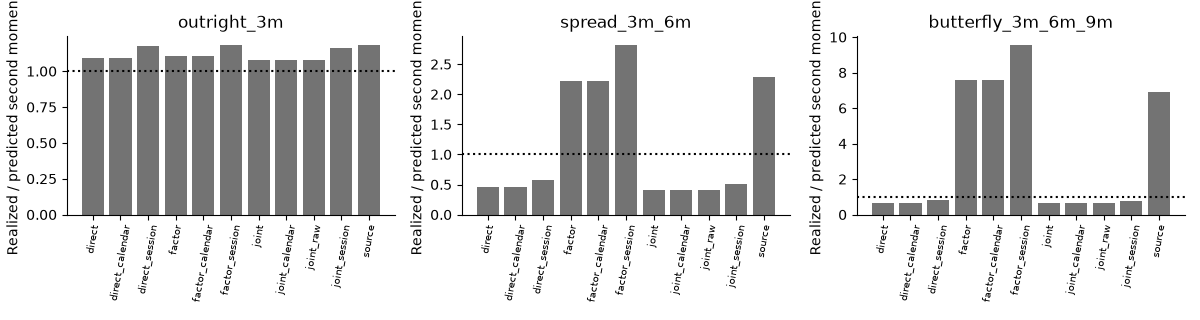

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, exposure in zip(axes, ["outright_3m", "spread_3m_6m", "butterfly_3m_6m_9m"], strict=True):
    rows = [r for r in joint["risk_summary"] if r["exposure"] == exposure]
    ax.bar(
        range(len(rows)), [r["realized_over_predicted_second_moment"] for r in rows], color="0.45"
    )
    ax.axhline(1, color="black", linestyle=":")
    ax.set_xticks(range(len(rows)), [r["method"] for r in rows], rotation=80, fontsize=7)
    ax.set(title=exposure, ylabel="Realized / predicted second moment")
fig.tight_layout()
plt.show()

## Cross-covariances and numerical checks

Dropping cross terms would impose independence without evidence. The components
below sum to a joint-model forecast; factor/direct controls can use a different
kernel. Numerical PSD/rank diagnostics establish matrix feasibility, not a
statistical or market-model guarantee. Availability is reported separately.

In [5]:
table(
    joint["risk_components"], ["method", "exposure", "count", "components_cny2", "cross_over_total"]
)
table(
    [r for r in joint["clock_gap_summary"] if r["method"] in ("joint_calendar", "joint_session")],
    ["method", "gap_group", "exposure", "count", "qlike", "realized_over_predicted_second_moment"],
)
print(json.dumps(joint["numerical_diagnostics"], indent=2))
print(json.dumps(joint["availability"], indent=2))

method | exposure | count | components_cny2 | cross_over_total
direct | outright_3m | 484 | {'factor': 11026392.28588151, 'residual': 121487.38436960395, 'cross': 148037.22066076426} | 0.0131054
direct_calendar | outright_3m | 484 | {'factor': 11026392.28588151, 'residual': 121487.38436960395, 'cross': 148037.22066076426} | 0.0131054
direct_session | outright_3m | 484 | {'factor': 10273652.344741207, 'residual': 94731.02120286341, 'cross': 115079.3105501842} | 0.0109772
factor | outright_3m | 484 | {'factor': 11026392.28588151, 'residual': 121487.38436960395, 'cross': 148037.22066076426} | 0.0131054
factor_calendar | outright_3m | 484 | {'factor': 11026392.28588151, 'residual': 121487.38436960395, 'cross': 148037.22066076426} | 0.0131054
factor_session | outright_3m | 484 | {'factor': 10273652.344741207, 'residual': 94731.02120286341, 'cross': 115079.3105501842} | 0.0109772
joint | outright_3m | 484 | {'factor': 11026392.28588151, 'residual': 121487.38436960395, 'cross': 148037.2206607

## Interpretation and next decision

Validation selects 63 intervals, calendar diffusion and zero shrinkage for the
joint model. Joint spread/butterfly QLIKE is 13.710/15.069, versus factor-only
15.172/23.760 and direct 13.637/15.066. Residual risk repairs the weak factor
model but does not establish superiority over direct covariance. Session scaling
improves curvature scores while worsening outright scores in this development
sample; the selected calendar policy remains unchanged.

Compare the selected practical policies and the fixed-clock companions separately.
Residual risk and a different clock can improve a weak factor forecast without
establishing an SPDE advantage over raw direct risk. Use the matched attribution
results and effective sample counts to qualify the conclusion. Test the selected
revised policy on an uninspected period before promoting it beyond development.

## Reproduction and research boundary

This notebook reads checksummed aggregate evidence, not raw exchange files.
The numerical algorithms are in `spde_covariance`; use the
[protocol](../docs/empirical-research-protocol.md) to rerun local calibration.
Execute this notebook with `uv run python scripts/check_notebook.py notebooks/05_joint_residual_risk_and_clocks.ipynb`.

The original historical benchmark remains fixed. New analyses on the inspected
2024–2025 period are exploratory, even though forecast issuance is past-only.
No final untouched confirmation period, executable trading backtest or physical
forcing identification is claimed. See the [roadmap](../README.md).